Breguet cruise fraction at 825 nmi: W3/W2 = 0.932090
Sizing cruise fraction:                    W3/W2 = 0.932135

MTOW: 50,696.7 lb
Max-payload/full-fuel TOW: 50,681.9 lb
MTOW margin: 14.8 lb

Calculated max-payload range: 819.5 nmi
Design range:                 825.0 nmi
Calculated ferry range:       1550.4 nmi


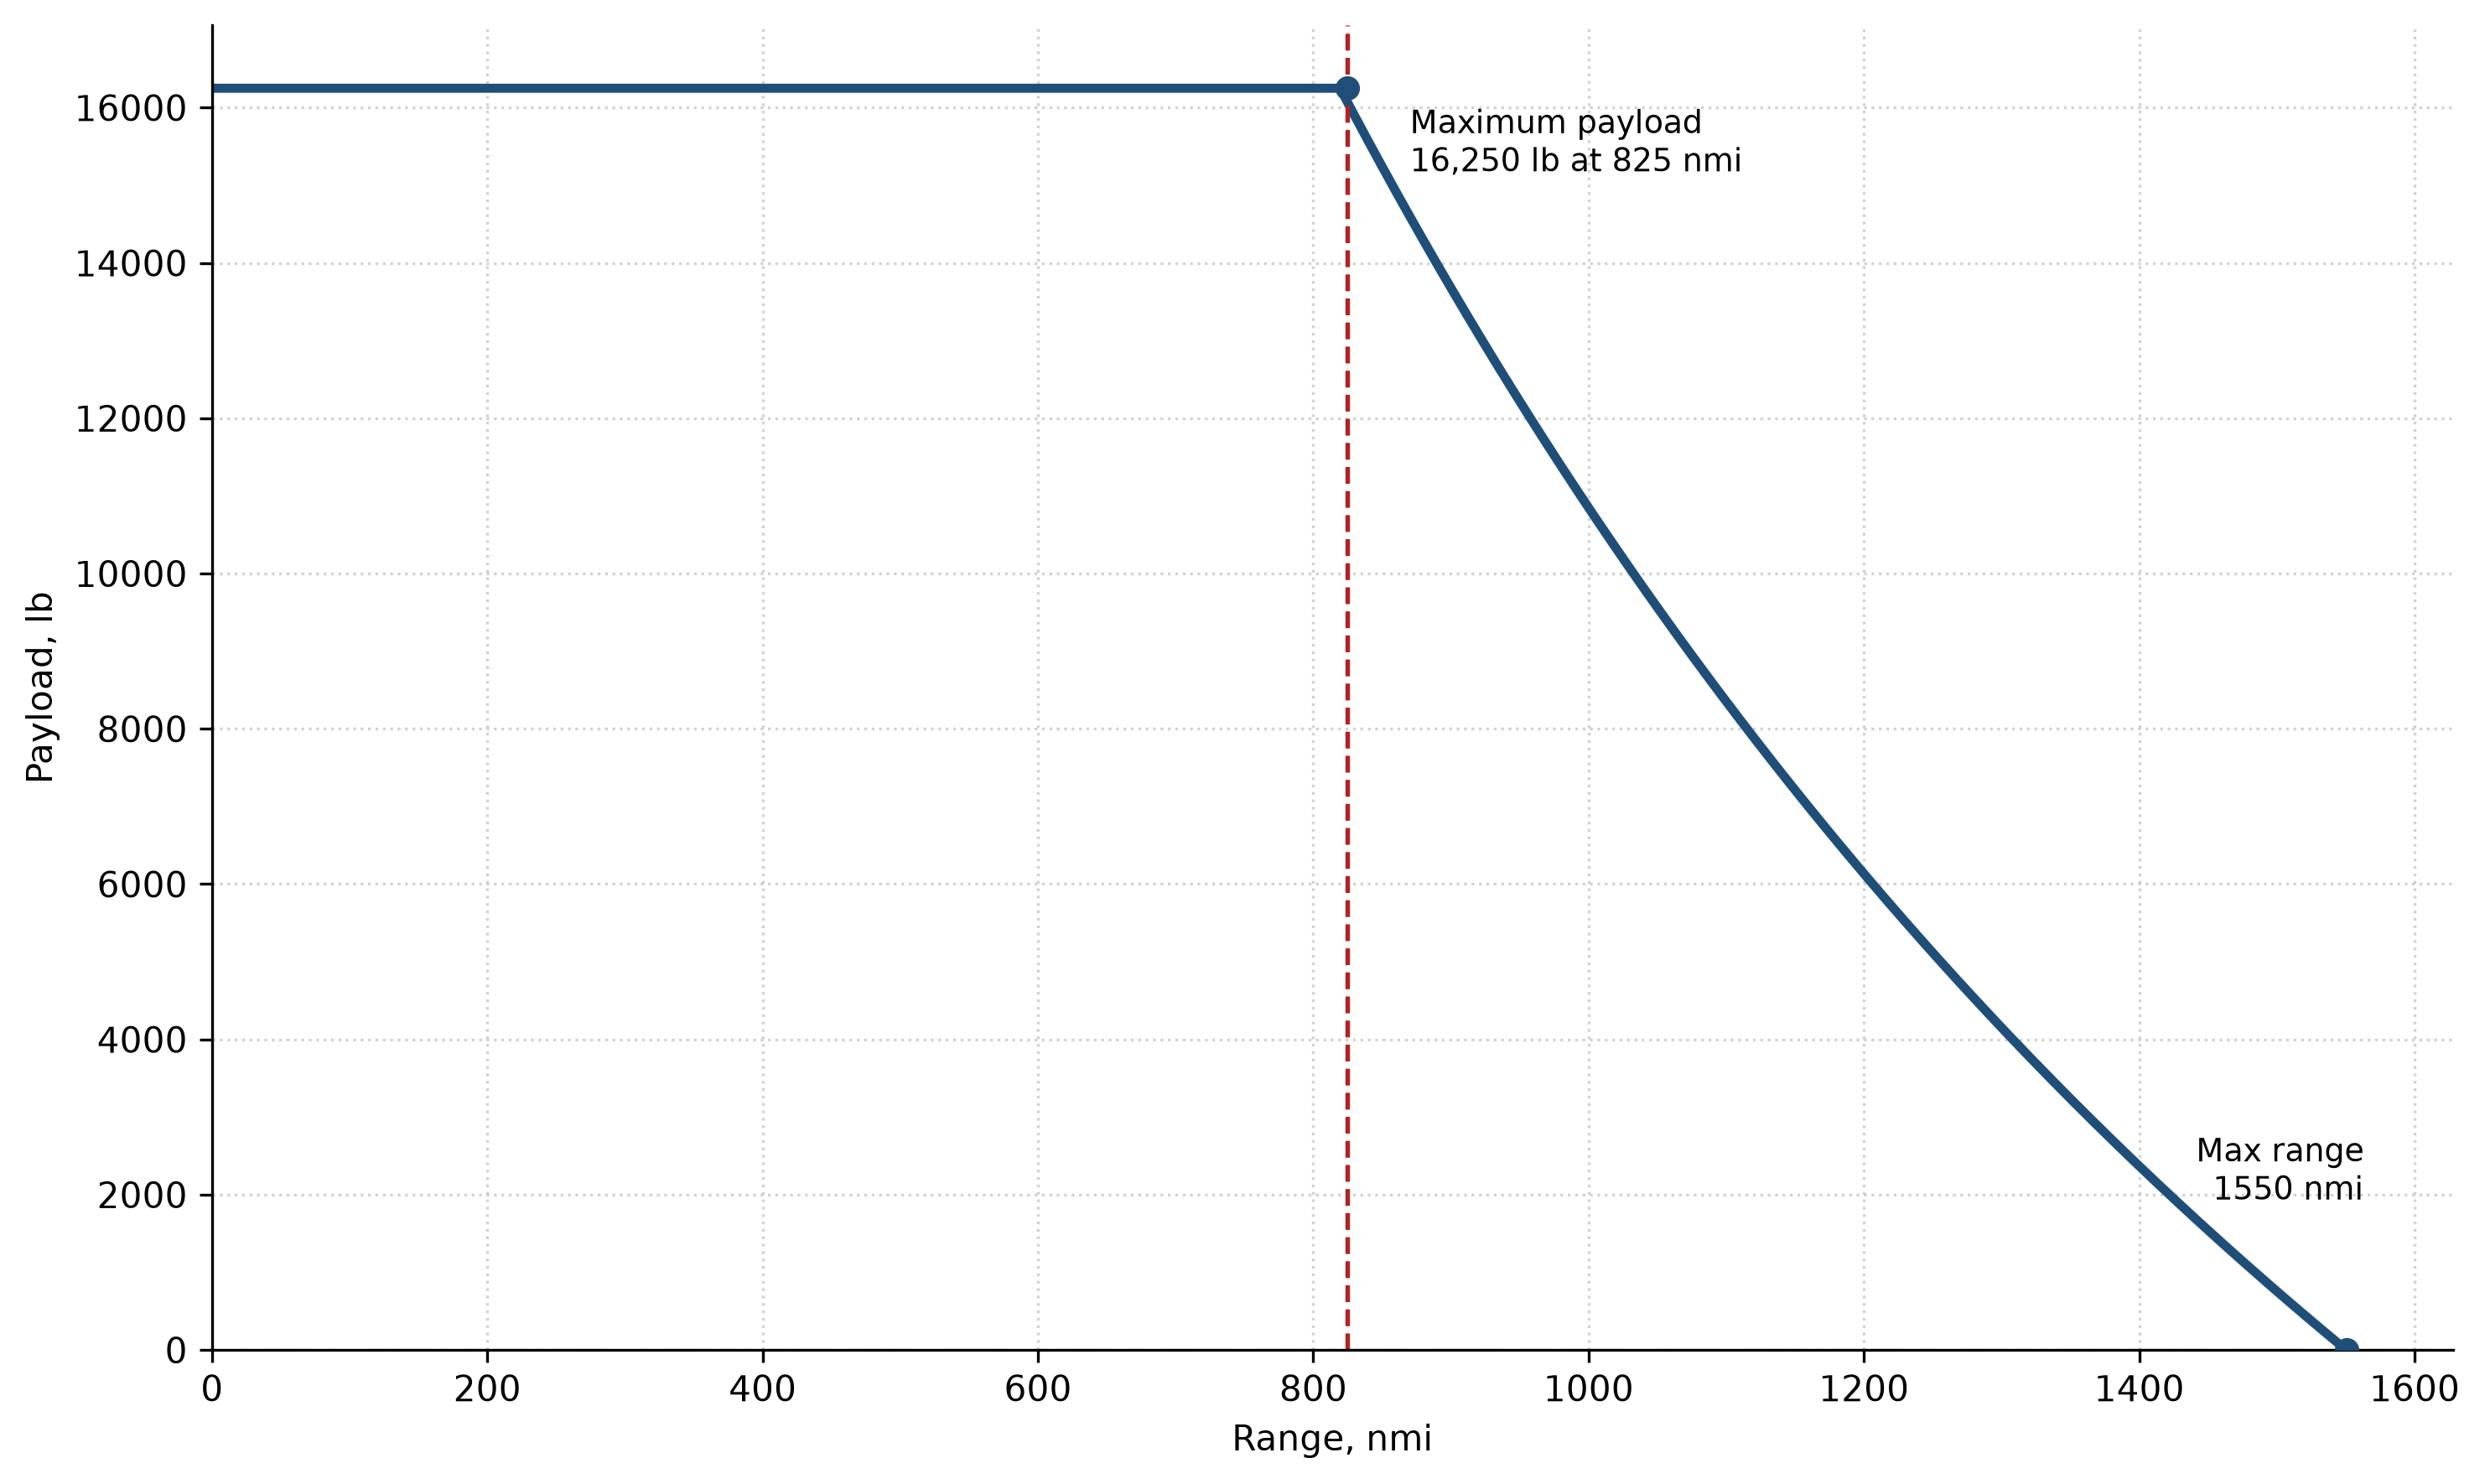

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Aircraft weights [lb]
MTOW = 50696.72136
W_E = 28314.05772
W_pl_max = 16250.0
W_f_capacity = 6117.851136

# Design mission
R_design = 825.0                 # nmi
L_D = 16.0
BSFC = 0.40                      # lb/(hp·hr); consistent with sizing cruise fraction
eta_p = 0.90
reserve_fraction = 0.06

# Mission weight fractions from sizing
f_takeoff = 0.970
f_climb = 0.985
f_landing = 0.995

# Fraction before the cruise segment: W2/W0
f_pre_cruise = f_takeoff * f_climb

# Propeller Breguet factor:
# R [nmi] = K * ln(W2 / W3)
K_breguet = (
    550 * 3600 * eta_p / BSFC
    * L_D
    / 6076.12
)

# Check that the Breguet assumptions reproduce the sizing cruise fraction
f_cruise_at_design = np.exp(-R_design / K_breguet)

print(f"Breguet cruise fraction at {R_design:.0f} nmi: "
      f"W3/W2 = {f_cruise_at_design:.6f}")
print("Sizing cruise fraction:                    "
      "W3/W2 = 0.932135")

# Fuel that may actually be consumed during the complete mission.
# The remaining fraction remains aboard as reserve.
W_f_burn_allowed = W_f_capacity * (1 - reserve_fraction)

# Payload values from maximum payload to ferry condition
payload = np.linspace(W_pl_max, 0, 250)

# This assumes full fuel is carried at every payload shown.
# Since full-fuel/max-payload takeoff weight is essentially MTOW,
# all lower-payload points are also below MTOW.
W0 = W_E + payload + W_f_capacity

# Full mission fuel balance:
#
# W4/W0 = (W1/W0)(W2/W1)(W3/W2)(W4/W3)
# W4    = W0 - usable mission fuel
#
# Therefore solve for the required cruise weight fraction W3/W2.
W4 = W0 - W_f_burn_allowed

f_cruise = W4 / (W0 * f_pre_cruise * f_landing)

# Breguet range for each full-fuel payload condition
range_nm = K_breguet * np.log(1 / f_cruise)

# Key payload-range points
R_max_payload = range_nm[0]
R_ferry = range_nm[-1]

# Check the full-fuel maximum-payload condition
W_TO_max_payload = W_E + W_pl_max + W_f_capacity
print(f"\nMTOW: {MTOW:,.1f} lb")
print(f"Max-payload/full-fuel TOW: {W_TO_max_payload:,.1f} lb")
print(f"MTOW margin: {MTOW - W_TO_max_payload:,.1f} lb")
print(f"\nCalculated max-payload range: {R_max_payload:.1f} nmi")
print(f"Design range:                 {R_design:.1f} nmi")
print(f"Calculated ferry range:       {R_ferry:.1f} nmi")

# Add the horizontal maximum-payload segment
plot_range = np.concatenate(([0], range_nm))
plot_payload = np.concatenate(([W_pl_max], payload))

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

ax.plot(plot_range, plot_payload, color="#1f4e79", linewidth=2.6)

# Design corner / calculated corner
ax.scatter(
    [R_design, R_ferry],
    [W_pl_max, 0],
    color="#1f4e79",
    s=36,
    zorder=3,
)

ax.axvline(R_design, color="#b22222", linestyle="--", linewidth=1.3)

ax.annotate(
    f"Maximum payload\n{W_pl_max:,.0f} lb at {R_design:.0f} nmi",
    xy=(R_max_payload, W_pl_max),
    xytext=(20, -5),
    textcoords="offset points",
    ha="left",
    va="top",
    fontsize=9,
)


ax.annotate(
    f"Max range\n{R_ferry:.0f} nmi",
    xy=(R_ferry, 0),
    xytext=(5, 40),
    textcoords="offset points",
    ha="right",
    va="bottom",
    fontsize=9,
)

ax.set_xlabel("Range, nmi")
ax.set_ylabel("Payload, lb")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.grid(True, linestyle=":", alpha=0.55)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig("Payload_range.png", dpi=300, bbox_inches="tight")
plt.show()